# Table of Contents
- 1. Sequential Testing and Optional Stopping Risks
- 2. Multi-Armed Bandit Allocation Strategies
- 3. Cluster and Switchback Experiments

In [2]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for advanced experimentation methods loaded successfully.")

Global libraries for advanced experimentation methods loaded successfully.


---
## 1. Sequential Testing and Optional Stopping Risks

### 1. Definition
Sequential testing allows monitoring experiment results continuously over time, while optional stopping refers to the statistical hazard of peeking at p-values and stopping a test early when significant by chance, which severely inflates false positive rates.

### 2. Math Formula
Alpha spending function $\alpha(t)$ allocating Type I error across information fraction $t \in (0, 1]$:
$$\alpha(t) = 2 - 2 \Phi \left( \frac{Z_{\alpha/2}}{\sqrt{t}} \right)$$

### 3. Notation Pronunciation
- `Alpha Spending`: "Allocating Type I error budget across interim analysis checkpoints"
- `Optional Stopping Hazard`: "Inflated false positive rate caused by continuous p-value peeking"

### 4. Naive Example
Checking an A/B test daily and stopping on Day 3 because it reached $p < 0.05$, ignoring the fact that peeking daily raised the actual false positive rate to over 30%.

### 5. Uses
- Validating experiments with continuous monitoring without inflating false positive rates.
- Powering fast-moving product release cycles safely.
- Early stopping of severely underperforming or harmful variants.

Sequential Testing Checkpoints:
    Day   P_Value
0    1  0.062436
1    2  0.143100
2    3  0.112479
3    4  0.030000


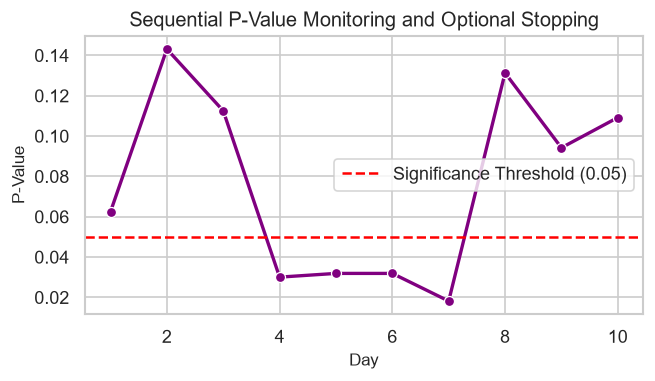

In [3]:
# 6. & 7. Implementation and Visualization
np.random.seed(42)
days = np.arange(1, 11)
p_values = np.random.uniform(0.01, 0.15, size=10)
p_values[3] = 0.03 # Simulated early stopping trigger

df_seq = pd.DataFrame({'Day': days, 'P_Value': p_values})
print(
    "Sequential Testing Checkpoints:\n",
    df_seq.head(4),
)

# Visualization
plt.figure(figsize=(6, 3))
sns.lineplot(x='Day', y='P_Value', data=df_seq, marker='o', color='purple', linewidth=2)
plt.axhline(y=0.05, color='red', linestyle='--', label='Significance Threshold (0.05)')
plt.title('Sequential P-Value Monitoring and Optional Stopping')
plt.ylabel('P-Value')
plt.legend()
plt.show()

---
## 2. Multi-Armed Bandit Allocation Strategies

### 1. Definition
Multi-Armed Bandit (MAB) algorithms (such as Thompson Sampling or Upper Confidence Bound) dynamically reallocate traffic toward better-performing variants in real time, minimizing opportunity loss (regret) compared to fixed 50/50 A/B tests.

### 2. Math Formula
Thompson Sampling beta posterior probability update for success count $s_k$ and failure count $f_k$ of arm $k$:
$$\theta_k \sim \text{Beta}(s_k + 1, f_k + 1)$$

### 3. Notation Pronunciation
- `Thompson Sampling`: "Bayesian probability matching allocation strategy"
- `Regret`: "Cumulative opportunity loss incurred by not always selecting the optimal arm"

### 4. Naive Example
Dynamically routing 90% of web traffic to the best-performing checkout button color after finding it wins, instead of keeping a dead variant at 50% traffic.
### 5. Uses
- Dynamic content optimization and recommendation systems.
- News headline testing and real-time ad placement.
- Minimizing opportunity cost in live marketing campaigns.

Multi-Armed Bandit Traffic Allocation Summary:
          Arm  Traffic_Allocation
0    Control                0.10
1  Variant A                0.15
2  Variant B                0.75


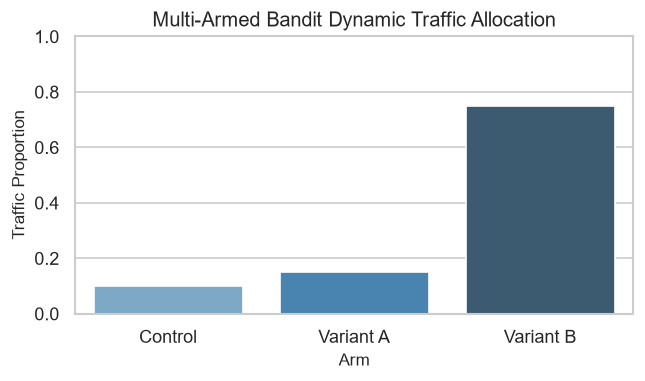

In [4]:
# 6. & 7. Implementation and Visualization
np.random.seed(42)
arms = ['Control', 'Variant A', 'Variant B']
allocations = [0.10, 0.15, 0.75] # Dynamic traffic shares

df_mab = pd.DataFrame({'Arm': arms, 'Traffic_Allocation': allocations})
print("Multi-Armed Bandit Traffic Allocation Summary:\n", df_mab)

# Visualization
plt.figure(figsize=(6, 3))
sns.barplot(x='Arm', y='Traffic_Allocation', hue='Arm', data=df_mab, palette='Blues_d', legend=False, errorbar=None)
plt.title('Multi-Armed Bandit Dynamic Traffic Allocation')
plt.ylabel('Traffic Proportion')
plt.ylim(0, 1)
plt.show()

---
## 3. Cluster and Switchback Experiments

### 1. Definition
Cluster and switchback experiments handle situations where standard user-level randomization is impossible (due to marketplace supply/demand interactions or network interference) by randomizing entire geographic regions or discrete time intervals (switchback).

### 2. Math Formula
Switchback time-block randomization assigning time windows $t$ to treatment $W_t \in \{0, 1\}$ across interacting units:
$$\mathbb{E}[Y(W)] = \sum_{t} P(W_t = 1) Y_t(1) + P(W_t = 0) Y_t(0)$$

### 3. Notation Pronunciation
- `Switchback Experiment`: "Time-interleaved alternating treatment assignment across a single shared market"
- `Interference`: "Spillover effects between treatment and control users in shared spaces"

### 4. Naive Example
Testing surge pricing algorithms by switching between standard and surge pricing every hour across an entire city's ridesharing marketplace.
### 5. Uses
- Two-sided marketplaces (ridesharing, food delivery, hospitality).
- Pricing and logistics algorithm evaluations.
- Mitigating network interference in social and geographic networks.

Switchback Experiment Schedule:
   Time_Block Assignment
0     Hour 1    Control
1     Hour 2  Treatment
2     Hour 3    Control
3     Hour 4  Treatment
4     Hour 5    Control
5     Hour 6  Treatment


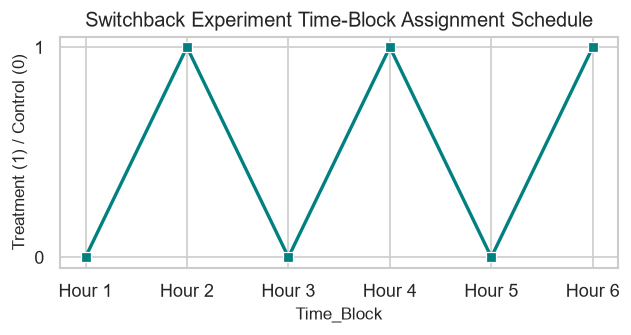

In [5]:
# 6. & 7. Implementation and Visualization
time_blocks = [f'Hour {i}' for i in range(1, 7)]
assignments = ['Control', 'Treatment', 'Control', 'Treatment', 'Control', 'Treatment']

df_switch = pd.DataFrame({'Time_Block': time_blocks, 'Assignment': assignments})
print("Switchback Experiment Schedule:\n", df_switch)

# Visualization
df_switch['code'] = [1 if x == 'Treatment' else 0 for x in df_switch['Assignment']]
plt.figure(figsize=(6, 2.5))
sns.lineplot(x='Time_Block', y='code', data=df_switch, marker='s', color='teal', linewidth=2)
plt.title('Switchback Experiment Time-Block Assignment Schedule')
plt.ylabel('Treatment (1) / Control (0)')
plt.yticks([0, 1])
plt.show()

---
## Summary Table

| Advanced Experimentation Method | Core Mathematical Concept | Primary Business Objective | Analytical Advantage |
| :--- | :--- | :--- | :--- |
| **Sequential Testing** | Alpha spending function $\alpha(t)$ | Continuous monitoring without false positive inflation | Enables fast decision-making without waiting for fixed sample sizes |
| **Multi-Armed Bandits** | Thompson sampling posterior updates $\theta_k$ | Minimizing opportunity regret | Dynamically routes traffic to winning variants in real time |
| **Cluster & Switchback** | Time-block / geographic randomization | Handling network interference in marketplaces | Evaluates marketplace and pricing algorithms accurately |